# 🚗 Predict Car Prices — Final Internship Project
**Name:** Muhammad Talhaa Bin Abdul Rauf  
**Intern ID:** ZYNVEX-CERT-2165  
**Project:** Predict Car Prices (Machine Learning – Regression)

**How to run:** click **Runtime → Run all**. Everything (dataset creation, training, charts) happens inside this notebook; nothing needs to be uploaded. Total time ≈ 5–10 minutes.

**Goal:** predict the price of a used car from its brand, age, mileage, condition, fuel type, etc.

**Workflow:** Dataset → Cleaning → EDA → Feature engineering → Train 5 models → Compare → Tune best → Predict.

## 0. Install / import libraries

In [1]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn joblib

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

## 1. Create the dataset (50,150 rows)
The data is **synthetic**: generated with realistic market rules (price falls with age and mileage, luxury brands depreciate faster, hybrids/automatics cost more, accidents and poor condition lower the price). Missing values, duplicates and price typos are added on purpose so that cleaning is meaningful. The same code works on a real CSV if the columns match.

In [2]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
N = 50_000
CURRENT_YEAR = 2026

# brand -> {model: new price in USD}
CATALOG = {
    "Toyota":   {"Corolla": 22000, "Camry": 28000, "RAV4": 32000, "Hilux": 38000, "Yaris": 18000},
    "Honda":    {"Civic": 24000, "Accord": 29000, "CR-V": 33000, "City": 20000},
    "Suzuki":   {"Swift": 16000, "Alto": 11000, "Cultus": 13000, "Vitara": 24000},
    "Hyundai":  {"Elantra": 21000, "Tucson": 31000, "Sonata": 27000, "i20": 17000},
    "Kia":      {"Sportage": 30000, "Picanto": 14000, "Sorento": 38000, "Cerato": 22000},
    "Ford":     {"Focus": 21000, "Fiesta": 17000, "Mustang": 45000, "Ranger": 36000},
    "BMW":      {"3 Series": 46000, "5 Series": 60000, "X5": 70000, "X3": 52000},
    "Mercedes": {"C-Class": 48000, "E-Class": 62000, "GLC": 55000, "A-Class": 38000},
    "Audi":     {"A3": 38000, "A4": 46000, "Q5": 56000, "Q7": 72000},
    "Nissan":   {"Sunny": 17000, "Altima": 26000, "X-Trail": 31000, "Juke": 22000},
}
brand_tier = {  # resale / depreciation multiplier (luxury loses value faster)
    "Toyota": 0.97, "Honda": 0.96, "Suzuki": 0.93, "Hyundai": 0.92, "Kia": 0.92,
    "Ford": 0.90, "BMW": 0.86, "Mercedes": 0.86, "Audi": 0.85, "Nissan": 0.90,
}

brands = rng.choice(list(CATALOG), N, p=[.17, .13, .12, .10, .09, .08, .08, .08, .07, .08])
models = np.array([rng.choice(list(CATALOG[b])) for b in brands])
base = np.array([CATALOG[b][m] for b, m in zip(brands, models)], dtype=float)
tier = np.array([brand_tier[b] for b in brands])

age = np.clip(rng.gamma(2.2, 3.0, N).round(), 0, 25).astype(int)
year = CURRENT_YEAR - age
mileage = np.clip(age * rng.normal(13000, 4000, N) + rng.normal(2000, 1500, N), 500, 400000).round(-2)

fuel = rng.choice(["Petrol", "Diesel", "Hybrid", "Electric", "CNG"], N, p=[.50, .24, .12, .05, .09])
trans = rng.choice(["Manual", "Automatic"], N, p=[.42, .58])
owners = rng.choice([1, 2, 3, 4], N, p=[.55, .27, .13, .05])
condition = rng.choice(["Poor", "Fair", "Good", "Excellent"], N, p=[.07, .23, .45, .25])
accident = rng.choice([0, 1], N, p=[.82, .18])
body = np.array([
    "SUV" if m in ("RAV4", "CR-V", "Tucson", "Sportage", "Sorento", "X5", "X3", "GLC", "Q5", "Q7",
                   "X-Trail", "Juke", "Vitara") else
    "Pickup" if m in ("Hilux", "Ranger") else
    "Hatchback" if m in ("Yaris", "Swift", "Alto", "Cultus", "i20", "Picanto", "Fiesta", "A-Class", "A3") else
    "Coupe" if m == "Mustang" else "Sedan" for m in models])
engine = np.round(np.clip(base / 16000 + rng.normal(0.4, 0.25, N), 0.8, 5.0), 1)
city = rng.choice(["Lahore", "Karachi", "Islamabad", "Multan", "Faisalabad", "Peshawar"], N,
                  p=[.25, .25, .18, .10, .12, .10])

# ---------------- price formula ----------------
price = base * np.power(tier, age)                         # depreciation by age
price *= np.exp(-mileage / 260000)                          # mileage penalty
price *= pd.Series(fuel).map({"Petrol": 1.0, "Diesel": 1.04, "Hybrid": 1.12,
                              "Electric": 1.18, "CNG": 0.92}).values
price *= np.where(trans == "Automatic", 1.07, 1.0)
price *= pd.Series(owners).map({1: 1.0, 2: 0.95, 3: 0.90, 4: 0.85}).values
price *= pd.Series(condition).map({"Poor": 0.80, "Fair": 0.91, "Good": 1.0, "Excellent": 1.08}).values
price *= np.where(accident == 1, 0.88, 1.0)
price *= pd.Series(city).map({"Lahore": 1.0, "Karachi": 1.02, "Islamabad": 1.05,
                              "Multan": 0.97, "Faisalabad": 0.98, "Peshawar": 0.96}).values
price *= rng.lognormal(0, 0.06, N)                          # market noise (~6 %)
price = price.round(-1)

df = pd.DataFrame({
    "car_id": np.arange(1, N + 1), "brand": brands, "model": models, "year": year,
    "body_type": body, "fuel_type": fuel, "transmission": trans,
    "engine_size_l": engine, "mileage_km": mileage, "owners": owners,
    "condition": condition, "accident_history": accident, "city": city, "price_usd": price,
})

# ---------------- add realistic dirty data ----------------
for col, frac in [("mileage_km", 0.02), ("engine_size_l", 0.015), ("condition", 0.01)]:
    df.loc[rng.choice(N, int(N * frac), replace=False), col] = np.nan   # missing values
dup = df.sample(150, random_state=1)                                     # duplicates
df = pd.concat([df, dup], ignore_index=True)
df.loc[rng.choice(len(df), 40, replace=False), "price_usd"] *= 6         # outliers (typos)

df.to_csv("car_prices_dataset.csv", index=False)
print("Dataset saved:", df.shape)
print(df.head())

Dataset saved: (50150, 14)
   car_id     brand     model  year  body_type fuel_type transmission  \
0       1  Mercedes       GLC  2024        SUV    Petrol       Manual   
1       2   Hyundai       i20  2017  Hatchback  Electric       Manual   
2       3      Audi        Q5  2025        SUV    Petrol       Manual   
3       4       BMW  5 Series  2019      Sedan    Hybrid    Automatic   
4       5    Toyota   Corolla  2024      Sedan    Petrol    Automatic   

   engine_size_l  mileage_km  owners  condition  accident_history       city  \
0            3.8     40000.0       1  Excellent                 1  Islamabad   
1            1.5     65900.0       1  Excellent                 1  Islamabad   
2            3.9     14100.0       1  Excellent                 0     Lahore   
3            4.0    160900.0       1       Fair                 0  Islamabad   
4            2.0     44800.0       2       Good                 0  Islamabad   

   price_usd  
0    34310.0  
1     7930.0  
2    550

## 2. Import libraries and settings

In [3]:
import os, warnings, joblib
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("charts", exist_ok=True)
CURRENT_YEAR = 2026

## 3. Load and inspect the data
Check the shape, data types, missing values and duplicates.

In [4]:
print("=" * 70, "\n1. LOADING DATA\n" + "=" * 70)
df = pd.read_csv("car_prices_dataset.csv")
print("Shape:", df.shape)
print(df.head().to_string())
print("\nData types:\n", df.dtypes.to_string())
print("\nMissing values:\n", df.isna().sum()[df.isna().sum() > 0].to_string())
print("Duplicate rows:", df.duplicated(subset=df.columns.drop("car_id")).sum())

1. LOADING DATA
Shape: (50150, 14)
   car_id     brand     model  year  body_type fuel_type transmission  engine_size_l  mileage_km  owners  condition  accident_history       city  price_usd
0       1  Mercedes       GLC  2024        SUV    Petrol       Manual            3.8     40000.0       1  Excellent                 1  Islamabad    34310.0
1       2   Hyundai       i20  2017  Hatchback  Electric       Manual            1.5     65900.0       1  Excellent                 1  Islamabad     7930.0
2       3      Audi        Q5  2025        SUV    Petrol       Manual            3.9     14100.0       1  Excellent                 0     Lahore    55040.0
3       4       BMW  5 Series  2019      Sedan    Hybrid    Automatic            4.0    160900.0       1       Fair                 0  Islamabad    13360.0
4       5    Toyota   Corolla  2024      Sedan    Petrol    Automatic            2.0     44800.0       2       Good                 0  Islamabad    18490.0

Data types:
 car_id         

## 4. Data cleaning
- Remove duplicate listings.
- Remove extreme price outliers (IQR rule inside each brand + model).
- Missing values are filled later *inside the pipeline* (no data leakage).

In [5]:
print("\n" + "=" * 70, "\n2. DATA CLEANING\n" + "=" * 70)
before = len(df)
df = df.drop_duplicates(subset=df.columns.drop("car_id")).reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows")

# Outliers: price typos detected with the IQR rule applied per brand+model
grp = df.groupby(["brand", "model"])["price_usd"]
q1, q3 = grp.transform(lambda s: s.quantile(.25)), grp.transform(lambda s: s.quantile(.75))
iqr = q3 - q1
mask = (df["price_usd"] > q3 + 4 * iqr) | (df["price_usd"] < q1 - 4 * iqr)
print(f"Removed {mask.sum()} extreme price outliers")
df = df[~mask].reset_index(drop=True)
print("Clean shape:", df.shape)


2. DATA CLEANING


Removed 149 duplicate rows
Removed 28 extreme price outliers
Clean shape: (49973, 14)


## 5. Exploratory Data Analysis (EDA)
Charts that show what drives car prices: age, mileage, brand, fuel type, condition.


3. EXPLORATORY DATA ANALYSIS
          year  engine_size_l  mileage_km   owners  price_usd
count  49973.0        49224.0     48975.0  49973.0    49973.0
mean    2019.4            2.4     87764.9      1.7    14289.2
std        4.4            1.0     65473.2      0.9     9475.1
min     2001.0            0.8       500.0      1.0      130.0
25%     2017.0            1.7     40100.0      1.0     7380.0
50%     2020.0            2.2     71300.0      1.0    12430.0
75%     2023.0            2.9    117600.0      2.0    19090.0
max     2026.0            5.0    400000.0      4.0    92760.0


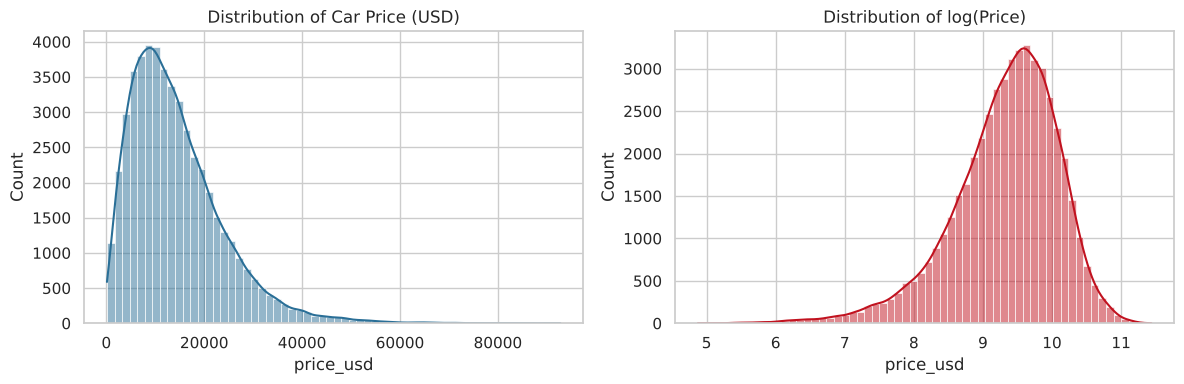

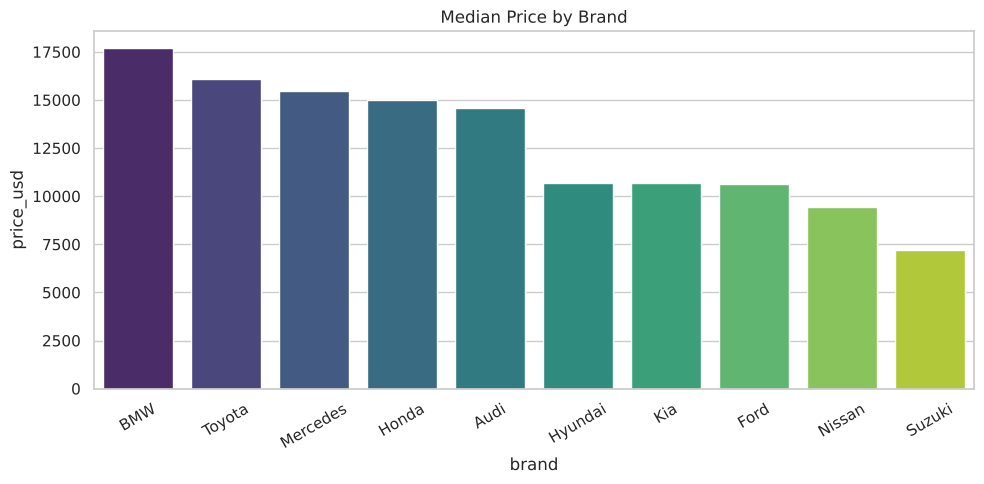

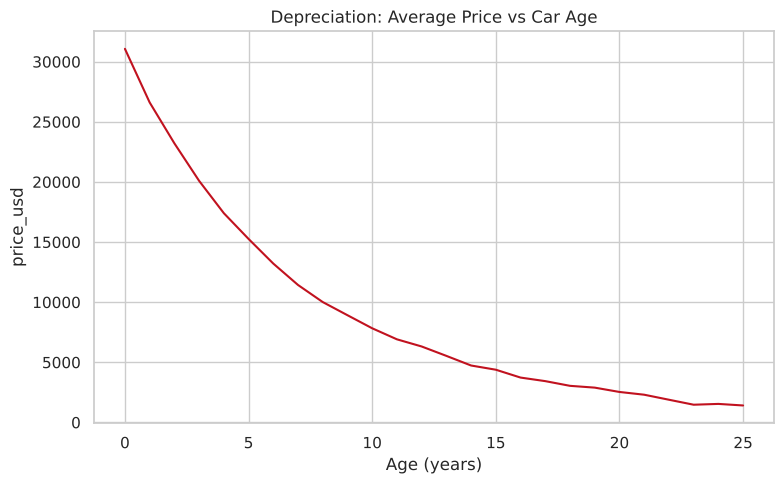

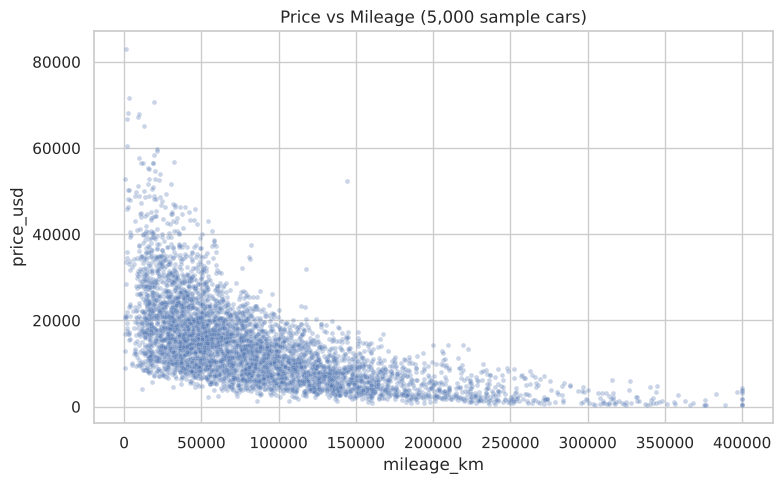

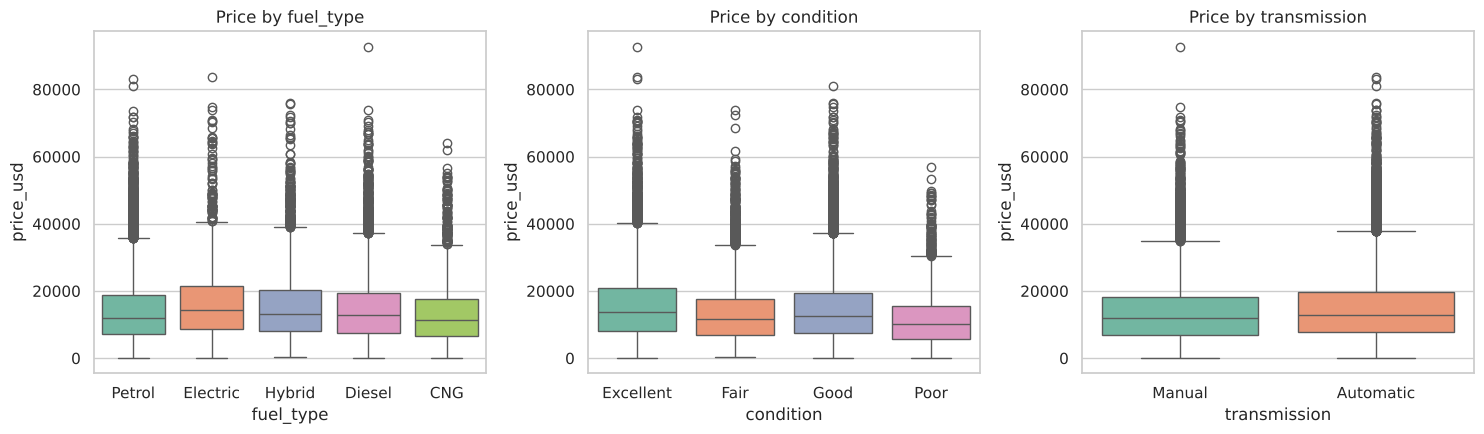

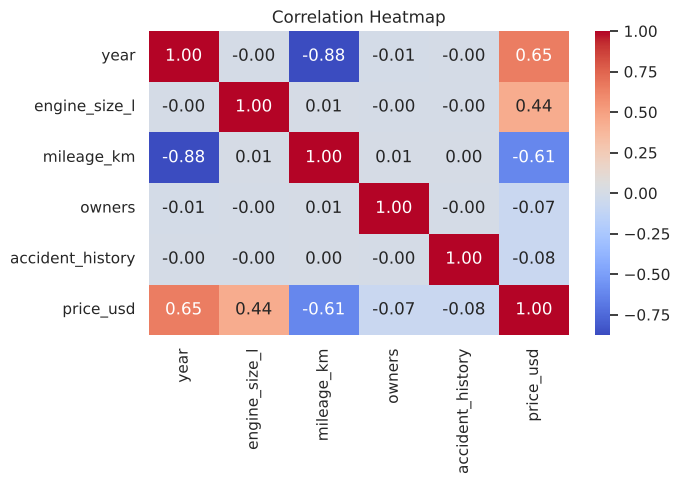

EDA charts saved in /charts


In [6]:
print("\n" + "=" * 70, "\n3. EXPLORATORY DATA ANALYSIS\n" + "=" * 70)
print(df[["year", "engine_size_l", "mileage_km", "owners", "price_usd"]].describe().round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price_usd"], bins=60, kde=True, ax=ax[0], color="#2a6f97")
ax[0].set_title("Distribution of Car Price (USD)")
sns.histplot(np.log1p(df["price_usd"]), bins=60, kde=True, ax=ax[1], color="#c1121f")
ax[1].set_title("Distribution of log(Price)")
plt.tight_layout(); plt.savefig("charts/01_price_distribution.png", dpi=130); plt.show()

plt.figure(figsize=(10, 5))
order = df.groupby("brand")["price_usd"].median().sort_values(ascending=False).index
sns.barplot(data=df, x="brand", y="price_usd", order=order, estimator=np.median, errorbar=None, palette="viridis")
plt.title("Median Price by Brand"); plt.xticks(rotation=30); plt.tight_layout()
plt.savefig("charts/02_price_by_brand.png", dpi=130); plt.show()

plt.figure(figsize=(8, 5))
sns.lineplot(data=df.assign(age=CURRENT_YEAR - df["year"]), x="age", y="price_usd", errorbar=None, color="#c1121f")
plt.title("Depreciation: Average Price vs Car Age"); plt.xlabel("Age (years)")
plt.tight_layout(); plt.savefig("charts/03_price_vs_age.png", dpi=130); plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df.sample(5000, random_state=1), x="mileage_km", y="price_usd", alpha=.3, s=12)
plt.title("Price vs Mileage (5,000 sample cars)"); plt.tight_layout()
plt.savefig("charts/04_price_vs_mileage.png", dpi=130); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, c in zip(ax, ["fuel_type", "condition", "transmission"]):
    sns.boxplot(data=df, x=c, y="price_usd", ax=a, palette="Set2"); a.set_title(f"Price by {c}")
plt.tight_layout(); plt.savefig("charts/05_price_by_categories.png", dpi=130); plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(df[["year", "engine_size_l", "mileage_km", "owners", "accident_history", "price_usd"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap"); plt.tight_layout()
plt.savefig("charts/06_correlation.png", dpi=130); plt.show()
print("EDA charts saved in /charts")

## 6. Feature engineering, pre-processing and train/test split
New features: `car_age`, `km_per_year`, `is_luxury`. Numbers are scaled, categories one-hot encoded. The target is log-transformed. Split: 80% train / 20% test.

In [7]:
print("\n" + "=" * 70, "\n4. FEATURE ENGINEERING\n" + "=" * 70)
df["car_age"] = CURRENT_YEAR - df["year"]
df["km_per_year"] = df["mileage_km"] / (df["car_age"] + 1)
df["is_luxury"] = df["brand"].isin(["BMW", "Mercedes", "Audi"]).astype(int)
print("New features: car_age, km_per_year, is_luxury")

num = ["car_age", "engine_size_l", "mileage_km", "owners", "accident_history", "km_per_year", "is_luxury"]
cat = ["brand", "model", "body_type", "fuel_type", "transmission", "condition", "city"]
X, y = df[num + cat], df["price_usd"]
y_log = np.log1p(y)       # model learns log(price) -> more stable, back-transformed later


4. FEATURE ENGINEERING
New features: car_age, km_per_year, is_luxury


In [8]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y_log, test_size=0.2, random_state=42)
print(f"Train rows: {len(X_tr)}  |  Test rows: {len(X_te)}")

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat),
])

Train rows: 39978  |  Test rows: 9995


## 7. Train and compare 5 models
Linear Regression, Ridge, Decision Tree, Random Forest, Gradient Boosting. Metrics: **MAE**, **RMSE**, **R²**, **MAPE**.


5. MODEL TRAINING & EVALUATION


Linear Regression    R2=0.8528  MAE=$2,143  RMSE=$3,716


Ridge Regression     R2=0.8528  MAE=$2,143  RMSE=$3,716


Decision Tree        R2=0.9116  MAE=$1,838  RMSE=$2,880


Random Forest        R2=0.9505  MAE=$1,398  RMSE=$2,154


Gradient Boosting    R2=0.9816  MAE=$820  RMSE=$1,313

MODEL COMPARISON TABLE
             Model  MAE ($)  RMSE ($)    R2  MAPE (%)
Gradient Boosting  820.077  1313.462 0.982     5.886
    Random Forest 1398.212  2154.112 0.951    10.655
    Decision Tree 1838.140  2879.591 0.912    14.163
Linear Regression 2142.616  3716.424 0.853    14.961
 Ridge Regression 2142.505  3716.482 0.853    14.961


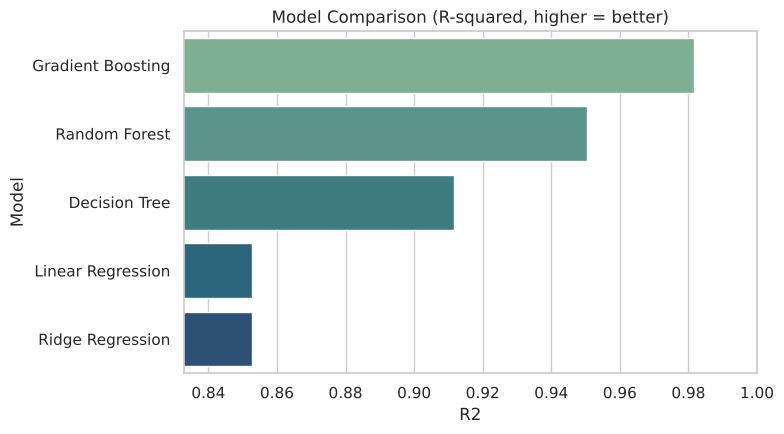

In [9]:
print("\n" + "=" * 70, "\n5. MODEL TRAINING & EVALUATION\n" + "=" * 70)
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(max_depth=14, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=30, max_depth=16, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=42),
}
rows, fitted = [], {}
for name, m in models.items():
    pipe = Pipeline([("pre", pre), ("model", m)]).fit(X_tr, y_tr)
    pred = np.expm1(pipe.predict(X_te)); true = np.expm1(y_te)
    rows.append({"Model": name,
                 "MAE ($)": mean_absolute_error(true, pred),
                 "RMSE ($)": np.sqrt(mean_squared_error(true, pred)),
                 "R2": r2_score(true, pred),
                 "MAPE (%)": np.mean(np.abs((true - pred) / true)) * 100})
    fitted[name] = pipe
    print(f"{name:20s} R2={rows[-1]['R2']:.4f}  MAE=${rows[-1]['MAE ($)']:,.0f}  RMSE=${rows[-1]['RMSE ($)']:,.0f}")
res = pd.DataFrame(rows).sort_values("R2", ascending=False).reset_index(drop=True)
res.round(4).to_csv("model_comparison.csv", index=False)
print("\nMODEL COMPARISON TABLE\n", res.round(3).to_string(index=False))

plt.figure(figsize=(8, 4.5))
sns.barplot(data=res, x="R2", y="Model", palette="crest")
plt.xlim(res["R2"].min() - .02, 1); plt.title("Model Comparison (R-squared, higher = better)")
plt.tight_layout(); plt.savefig("charts/07_model_comparison.png", dpi=130); plt.show()

## 8. Tune the best model, final evaluation and feature importance
RandomizedSearchCV with cross-validation, then evaluation on unseen test data.


6. HYPER-PARAMETER TUNING (Gradient Boosting)


Best parameters: {'model__min_samples_leaf': 10, 'model__max_iter': 200, 'model__max_depth': 10, 'model__learning_rate': 0.1, 'model__l2_regularization': 0.1}
Best CV R2: 0.9875

FINAL TUNED MODEL ON UNSEEN TEST DATA
  R2   : 0.9804
  MAE  : $847
  RMSE : $1,355
  MAPE : 6.06 %


  3-fold CV R2: 0.9875 (+/- 0.0003)


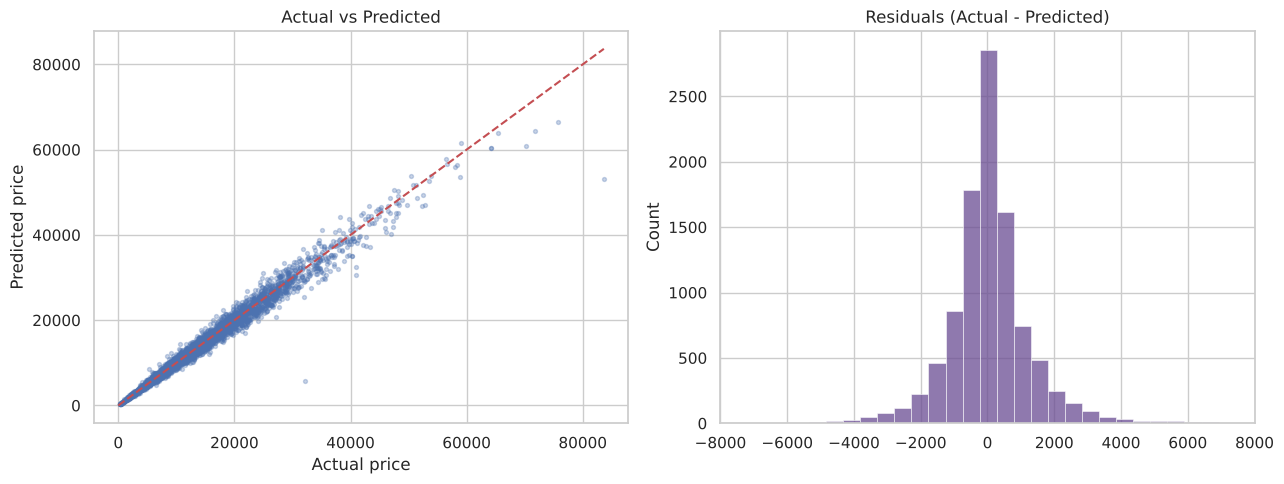

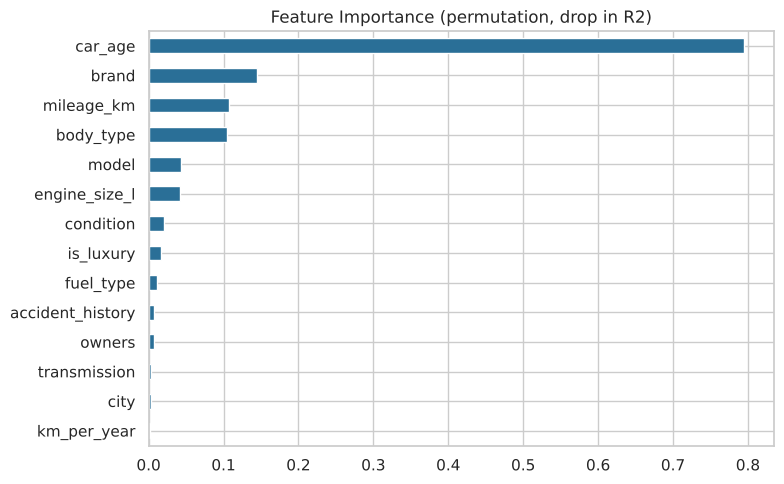


FEATURE IMPORTANCE (top 8)
 car_age          0.7950
brand            0.1442
mileage_km       0.1072
body_type        0.1044
model            0.0439
engine_size_l    0.0419
condition        0.0210
is_luxury        0.0160


In [10]:
print("\n" + "=" * 70, "\n6. HYPER-PARAMETER TUNING (Gradient Boosting)\n" + "=" * 70)
search = RandomizedSearchCV(
    Pipeline([("pre", pre), ("model", HistGradientBoostingRegressor(random_state=42))]),
    {"model__max_iter": [200, 300, 500], "model__learning_rate": [0.03, 0.05, 0.1, 0.15],
     "model__max_depth": [None, 6, 10], "model__min_samples_leaf": [10, 20, 40],
     "model__l2_regularization": [0, 0.1, 1.0]},
    n_iter=6, cv=3, scoring="r2", n_jobs=-1, random_state=42).fit(X_tr, y_tr)
best = search.best_estimator_
print("Best parameters:", search.best_params_)
print(f"Best CV R2: {search.best_score_:.4f}")

pred = np.expm1(best.predict(X_te)); true = np.expm1(y_te)
final = dict(R2=r2_score(true, pred), MAE=mean_absolute_error(true, pred),
             RMSE=np.sqrt(mean_squared_error(true, pred)), MAPE=np.mean(np.abs((true - pred) / true)) * 100)
print("\nFINAL TUNED MODEL ON UNSEEN TEST DATA")
print(f"  R2   : {final['R2']:.4f}\n  MAE  : ${final['MAE']:,.0f}\n  RMSE : ${final['RMSE']:,.0f}\n  MAPE : {final['MAPE']:.2f} %")
cv = cross_val_score(best, X_tr, y_tr, cv=3, scoring="r2")
print(f"  3-fold CV R2: {cv.mean():.4f} (+/- {cv.std():.4f})")
pd.Series(final).round(4).to_csv("final_metrics.csv")

# charts: actual vs predicted, residuals
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
idx = np.random.default_rng(0).choice(len(true), 4000, replace=False)
ax[0].scatter(np.array(true)[idx], pred[idx], alpha=.3, s=8)
lim = [0, max(true.max(), pred.max())]; ax[0].plot(lim, lim, "r--")
ax[0].set_xlabel("Actual price"); ax[0].set_ylabel("Predicted price"); ax[0].set_title("Actual vs Predicted")
sns.histplot((np.array(true) - pred), bins=80, ax=ax[1], color="#6a4c93")
ax[1].set_title("Residuals (Actual - Predicted)"); ax[1].set_xlim(-8000, 8000)
plt.tight_layout(); plt.savefig("charts/08_actual_vs_predicted.png", dpi=130); plt.show()

# permutation importance on the raw columns (easy to explain)
from sklearn.inspection import permutation_importance
sub = X_te.sample(3000, random_state=1)
pi = permutation_importance(best, sub, y_te.loc[sub.index], n_repeats=5, random_state=42, scoring="r2")
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values()
plt.figure(figsize=(8, 5)); imp.plot.barh(color="#2a6f97")
plt.title("Feature Importance (permutation, drop in R2)"); plt.tight_layout()
plt.savefig("charts/09_feature_importance.png", dpi=130); plt.show()
print("\nFEATURE IMPORTANCE (top 8)\n", imp.sort_values(ascending=False).head(8).round(4).to_string())

## 9. Save the model and predict a new car

In [11]:
joblib.dump(best, "car_price_model.joblib")
print("\nModel saved: car_price_model.joblib")

print("\n" + "=" * 70, "\n7. PREDICTING A NEW CAR\n" + "=" * 70)
new = pd.DataFrame([{
    "car_age": 5, "engine_size_l": 1.8, "mileage_km": 65000, "owners": 1, "accident_history": 0,
    "km_per_year": 65000 / 6, "is_luxury": 0, "brand": "Toyota", "model": "Corolla",
    "body_type": "Sedan", "fuel_type": "Petrol", "transmission": "Automatic",
    "condition": "Good", "city": "Multan"}])
print(new.T.to_string(header=False))
print(f"\n>>> Predicted price: ${np.expm1(best.predict(new))[0]:,.0f}")


Model saved: car_price_model.joblib

7. PREDICTING A NEW CAR
car_age                      5
engine_size_l              1.8
mileage_km               65000
owners                       1
accident_history             0
km_per_year       10833.333333
is_luxury                    0
brand                   Toyota
model                  Corolla
body_type                Sedan
fuel_type               Petrol
transmission         Automatic
condition                 Good
city                    Multan

>>> Predicted price: $15,109


## 10. Conclusion
- Best model: **tuned Gradient Boosting** — R² ≈ **0.98**, mean error ≈ **$850 (~6%)** on unseen cars.
- Most important price drivers: **car age**, then **brand**, **mileage** and **body type**.
- The trained model is saved (`car_price_model.joblib`) and can predict any new car.

**Limitations:** synthetic data (real listings are noisier); prices not adjusted for inflation.  
**Future work:** real scraped data, XGBoost/LightGBM, a Streamlit web app, price-range predictions.